# **Stress Detection on WESAD — Classification Pipeline**

This notebook implements the classification stage of the WESAD stress-detection pipeline:
from the extracted feature tables to trained, tuned and explained models.

## Methodology
All models are validated with **Leave-One-Subject-Out (LOSO)** cross-validation: with only
15 subjects, subject-wise splitting is used instead of random window-level splitting to
avoid leakage from near-duplicate windows of the same subject. Every learned step,
imputation, scaling, feature selection and hyperparameter tuning, is fitted **inside** the
training folds through a nested cross-validation scheme, so the held-out subject never
influences the fitted pipeline. Given the class imbalance after segmentation, **F1-macro**
is the primary metric, with accuracy reported as a secondary reference.

## Structure
**1. Binary classification — stress vs. non-stress**
Four classifiers (Decision Tree, Naive Bayes, k-NN, Random Forest) are
compared under nested LOSO. Model differences are assessed with a Friedman test followed by
post-hoc Wilcoxon tests with Holm correction. A device comparison (chest vs. chest+wrist)
tests whether the wrist sensor adds discriminative value, with a feature-count grid scaled
to each configuration.

**2. Three-class classification — baseline vs. stress vs. amusement**
The same four models and statistical comparison are applied to the harder three-class task.
Errors concentrate on the amusement class, whose physiological signature is weak; two
targeted experiments probe whether this is fixable: SMOTE oversampling
and an analysis of feature-selection frequency across folds. The device
comparison is repeated here, where additional sensors would have the best chance to help.

**3. Explainability (SHAP)**
Because the statistical comparison finds the models equivalent, explainability is carried out
on Random Forest, which supports fast, exact tree-based SHAP. Global and local explanations
verify whether the model relies on physiologically meaningful features and shed light on the
amusement confusion, connecting back to the error analysis.

## Dependencies
`feature_selectors.py` (shared leakage-safe transformers) must sit next to this notebook.
External libraries: scikit-learn, imbalanced-learn (SMOTE), scipy (statistical tests),
shap (explainability), matplotlib, pandas, numpy.

## **0. Setup and imports**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import copy
from functools import partial

from sklearn.model_selection import LeaveOneGroupOut, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

from scipy.stats import friedmanchisquare, wilcoxon
from collections import Counter
from itertools import combinations

import shap

# Shared leakage-safe transformers from feature selection step
from feature_selectors import MissingnessFilter, CorrelationFilter

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

# Seeded mutual-information scorer
mi_clf = partial(mutual_info_classif, random_state=RANDOM_STATE)

In [2]:
# Paths to the feature CSVs
FEATURES_CSV = os.path.join('Preprocessing_and_Feature_Selection', 'Chest','chest_outputs', 'features.csv')
COMBINED_CSV = os.path.join('Preprocessing_and_Feature_Selection', 'Combined','combined_outputs', 'features_all.csv')

META = ['label', 'label_name', 'subject_id']   # non-feature columns
NA_THRESHOLD = 0.30                            # missingness cutoff, matches feature selection

In [3]:
# Load features and prepare data for classification
def load_features(path):
    """Load features from a CSV file, drop rows with missing subject_id or label, and convert types."""
    df = pd.read_csv(path)
    df = df.dropna(subset=['subject_id', 'label']).reset_index(drop=True)
    df['subject_id'] = df['subject_id'].astype(int)
    df['label'] = df['label'].astype(int)
    return df

features = load_features(FEATURES_CSV)
feature_cols = [c for c in features.columns if c not in META]

X = features[feature_cols].values
# Binary classification: stress (label= 2) vs non-stress (label= 1)
y_binary = (features['label'].values == 2).astype(int)   
groups = features['subject_id'].values

# Print dataset summary
n_stress = int(y_binary.sum())
print(f'{X.shape[0]} windows, {len(feature_cols)} features, {features["subject_id"].nunique()} subjects')
print(f'stress: {n_stress} ({n_stress / len(y_binary) * 100:.1f}%)  |  '
      f'non-stress: {len(y_binary) - n_stress} ({(1 - n_stress / len(y_binary)) * 100:.1f}%)')

6123 windows, 80 features, 15 subjects
stress: 1826 (29.8%)  |  non-stress: 4297 (70.2%)


In [4]:
# Helper function for select__k validation curves
def _k_curve_from_search(search):
    """From a fitted GridSearchCV, return {k: best mean_test_score at that k}."""
    res = search.cv_results_
    out = {}
    for i, p in enumerate(res['params']):
        k = p['select__k']
        s = res['mean_test_score'][i]
        if k not in out or s > out[k]:   # best over the other hyperparameters
            out[k] = s
    return out

## **1. Binary Classification pipeline**

Each classifier sits at the end of a shared preprocessing chain, fitted independently
inside every fold:

1. `MissingnessFilter` — drop columns missing in more than 30% of the fold's training rows.
2. `SimpleImputer` — median-fill the remaining gaps.
3. `StandardScaler` — standardise (needed for k-NN; harmless for the others).
4. `CorrelationFilter` — remove redundant features (|r| > 0.9), relevance-aware.
5. `SelectKBest` — keep the top-k features by mutual information.
6. the classifier.

Fitting the whole chain per fold keeps the evaluation leakage-free: the held-out
subject never contributes to imputation values, scaling statistics or feature ranking.

In [5]:
def make_pipeline(clf):
    """Create a machine learning pipeline with preprocessing and the specified classifier."""
    return Pipeline([
        ('missingness', MissingnessFilter(threshold=NA_THRESHOLD)),
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('redundancy', CorrelationFilter(threshold=0.9, random_state=RANDOM_STATE)),
        ('select', SelectKBest(mi_clf, k=15)),
        ('clf', clf),
    ])

# Evaluated classifiers (with class_weight='balanced' for imbalanced data)
models = {
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'Naive Bayes':   GaussianNB(),
    'k-NN':          KNeighborsClassifier(),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}

### 1.1 Hyperparameters grid
The number of selected features `k` is tuned as
a hyperparameter, jointly with each model's own parameters. `select__k` reaches the
`SelectKBest` step through the pipeline's `step__param` naming. The grids are deliberately
small to keep the nested search affordable under LOSO.

In [6]:
# Shared across models: how many features to keep after the filter
K_GRID = [10, 15, 20]

# Model-specific hyperparameter grids 
param_grids = {
    'Decision Tree': {
        'select__k': K_GRID,
        'clf__max_depth': [None, 5, 10],
        'clf__min_samples_leaf': [1, 5],
    },
    'Naive Bayes': {
        'select__k': K_GRID,
        'clf__var_smoothing': [1e-9, 1e-7, 1e-5],
    },
    'k-NN': {
        'select__k': K_GRID,
        'clf__n_neighbors': [5, 11, 21],
        'clf__weights': ['uniform', 'distance'],
    },
    'Random Forest': {
        'select__k': K_GRID,
        'clf__n_estimators': [200, 400],
        'clf__max_depth': [None, 10],
    },
}

### 1.2 Nested LOSO evaluation
Generalisation is estimated with an outer LOSO loop. Inside each outer fold the
hyperparameters are chosen by an inner LOSO search over the 14 training subjects
(`GridSearchCV` with `LeaveOneGroupOut`), so tuning never sees the held-out subject.
The tuned pipeline is then evaluated on that held-out subject. This yields a vector of 15
per-subject scores per model, then used for the plots and the following statistical tests.

In [7]:
# Nested Leave-One-Subject-Out (LOSO) cross-validation
outer_cv = LeaveOneGroupOut()
inner_cv = LeaveOneGroupOut()

def nested_loso(clf, param_grid, X, y, groups):
    """Perform nested LOSO cross-validation for a given classifier and parameter grid.
    Returns F1-macro scores, accuracy scores, chosen hyperparameters, predictions, probabilities, and k-curves."""
    f1_scores, acc_scores, chosen = [], [], []
    y_pred = np.empty_like(y)
    y_proba = np.full(len(y), np.nan)
    k_curves = []
    for train_idx, test_idx in outer_cv.split(X, y, groups):
        search = GridSearchCV(
            make_pipeline(clf), param_grid,
            scoring='f1_macro', cv=inner_cv, n_jobs=-1,
        )
        search.fit(X[train_idx], y[train_idx], groups=groups[train_idx])
        k_curves.append(_k_curve_from_search(search))
        y_pred[test_idx] = search.predict(X[test_idx])
        y_proba[test_idx] = search.predict_proba(X[test_idx])[:, 1]
        f1_scores.append(f1_score(y[test_idx], y_pred[test_idx], average='macro'))
        acc_scores.append(accuracy_score(y[test_idx], y_pred[test_idx]))
        chosen.append(search.best_params_)
    return np.array(f1_scores), np.array(acc_scores), chosen, y_pred, y_proba, k_curves

# Run nested LOSO for each model and store results
results_f1, results_acc, results_params, results_pred, results_proba, results_kcurves = {}, {}, {}, {}, {}, {}
for name, clf in models.items():
    print(f'Evaluating {name} ...')
    f1v, accv, chosen, ypred, yproba, kcurves = nested_loso(clf, param_grids[name], X, y_binary, groups)
    results_f1[name] = f1v
    results_acc[name] = accv
    results_params[name] = chosen
    results_pred[name] = ypred
    results_proba[name] = yproba
    results_kcurves[name] = kcurves
    print(f'  {name}: F1-macro {f1v.mean():.3f} +/- {f1v.std():.3f}   '
          f'accuracy {accv.mean():.3f} +/- {accv.std():.3f}')

Evaluating Decision Tree ...
  Decision Tree: F1-macro 0.770 +/- 0.150   accuracy 0.830 +/- 0.086
Evaluating Naive Bayes ...
  Naive Bayes: F1-macro 0.902 +/- 0.090   accuracy 0.913 +/- 0.083
Evaluating k-NN ...
  k-NN: F1-macro 0.805 +/- 0.212   accuracy 0.859 +/- 0.158
Evaluating Random Forest ...
  Random Forest: F1-macro 0.865 +/- 0.130   accuracy 0.903 +/- 0.082


### Store, summarize and visualize classification results

In [8]:
# Print the most frequent hyperparameter configuration for each model
for name in models:
    counts = Counter(tuple(sorted(p.items())) for p in results_params[name])
    top, freq = counts.most_common(1)[0]
    print(f'{name}: most frequent config ({freq}/15 folds)')
    for key, val in top:
        print(f'    {key} = {val}')

Decision Tree: most frequent config (4/15 folds)
    clf__max_depth = 5
    clf__min_samples_leaf = 1
    select__k = 20
Naive Bayes: most frequent config (13/15 folds)
    clf__var_smoothing = 1e-09
    select__k = 20
k-NN: most frequent config (4/15 folds)
    clf__n_neighbors = 21
    clf__weights = distance
    select__k = 20
Random Forest: most frequent config (5/15 folds)
    clf__max_depth = 10
    clf__n_estimators = 200
    select__k = 20


In [9]:
# Plotting function for nested LOSO tuning curves
def plot_nested_k_curves(results_kcurves, title):
    """Average the per-outer-fold inner-CV tuning curves across the 15 folds."""
    fig, ax = plt.subplots(figsize=(8, 5))
    for name in models:
        curves = results_kcurves[name]
        ks = sorted(curves[0].keys())
        M = np.array([[c[k] for k in ks] for c in curves])
        mean, std = M.mean(axis=0), M.std(axis=0)
        ax.plot(ks, mean, marker='o', label=name)
        ax.fill_between(ks, mean - std, mean + std, alpha=0.15)
    ax.set_xlabel('Number of selected features (select__k)')
    ax.set_ylabel('Inner-LOSO F1-macro\n(mean over the 15 outer folds, best over other hyperparameters)')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

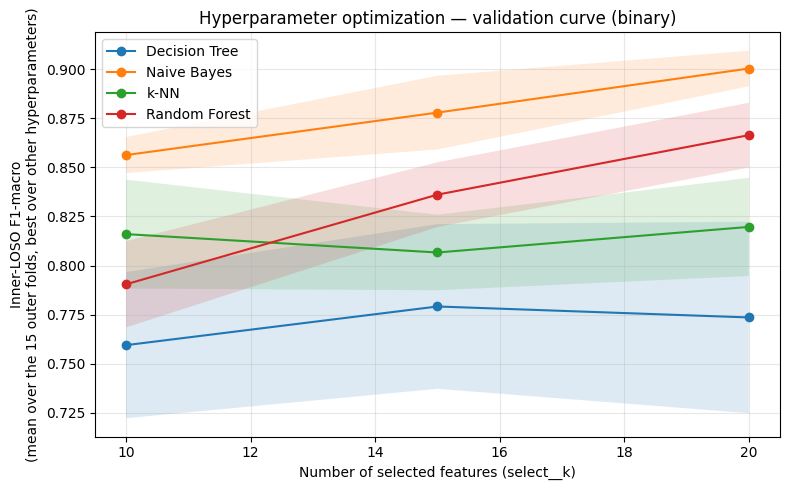

In [10]:
# Plot the nested LOSO tuning curves for the binary classification task
plot_nested_k_curves(results_kcurves, 
                     'Hyperparameter optimization — validation curve (binary)')

In [11]:
# Summarize results in a DataFrame for comparison
summary = pd.DataFrame({
    'F1-macro (mean)': {m: v.mean() for m, v in results_f1.items()},
    'F1-macro (std)':  {m: v.std()  for m, v in results_f1.items()},
    'Accuracy (mean)': {m: v.mean() for m, v in results_acc.items()},
    'Accuracy (std)':  {m: v.std()  for m, v in results_acc.items()},
}).round(3)
summary

,F1-macro (mean),F1-macro (std),Accuracy (mean),Accuracy (std)
Decision Tree,0.770,0.150,0.830,0.086
Naive Bayes,0.902,0.090,0.913,0.083
k-NN,0.805,0.212,0.859,0.158
Random Forest,0.865,0.130,0.903,0.082


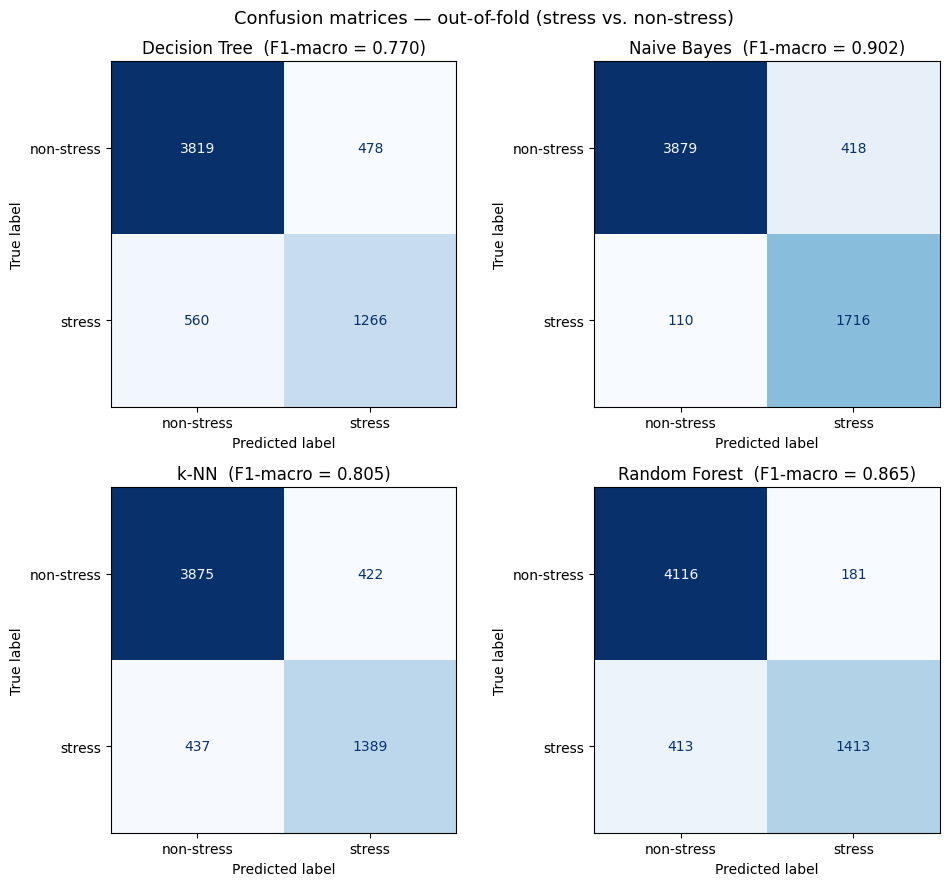

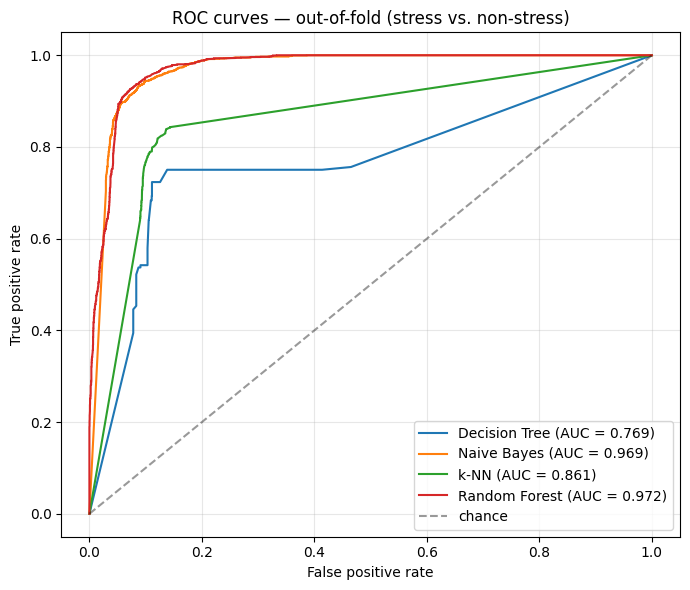

In [12]:
# Confusion matrices for all four models 
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_binary, results_pred[name])
    ConfusionMatrixDisplay(cm, display_labels=['non-stress', 'stress']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}  (F1-macro = {results_f1[name].mean():.3f})')
fig.suptitle('Confusion matrices — out-of-fold (stress vs. non-stress)', fontsize=13)
plt.tight_layout()
plt.show()

# ROC curves for all four models on one axis
fig, ax = plt.subplots(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_binary, results_proba[name])
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='chance')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves — out-of-fold (stress vs. non-stress)')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

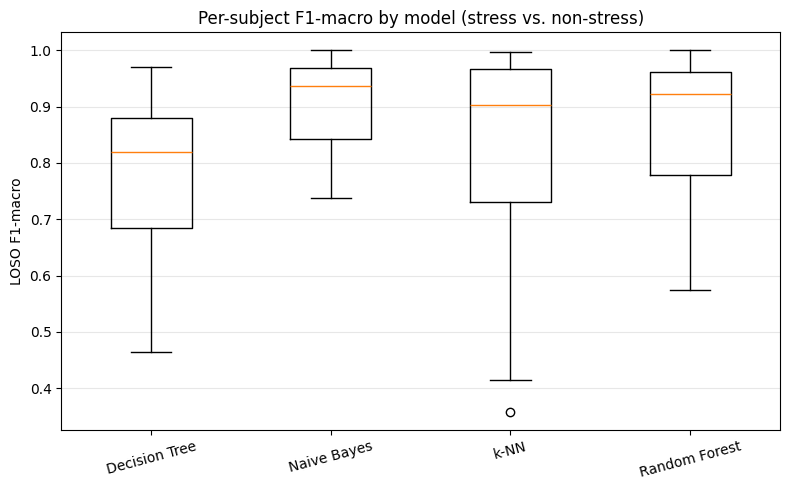

In [13]:
# Boxplots visual analysis for model comparison
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([results_f1[m] for m in models], tick_labels=list(models.keys()))
ax.set_ylabel('LOSO F1-macro')
ax.set_title('Per-subject F1-macro by model (stress vs. non-stress)')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 1.3 Statistical comparison
A Friedman test checks whether the four models differ
overall; if it is significant, post-hoc pairwise Wilcoxon signed-rank tests with Holm
correction identify which pairs differ.

In [14]:
# Statistical analysis: Friedman omnibus test
score_matrix_bin = [results_f1[m] for m in models]
stat_bin, p_friedman_bin = friedmanchisquare(*score_matrix_bin)
print(f'Friedman: chi2 = {stat_bin:.3f}, p = {p_friedman_bin:.4f}')
if p_friedman_bin > 0.05:
    print('-> no significant overall difference between the four models')
else:
    print('-> the models differ; running post-hoc pairwise Wilcoxon (Holm-corrected)')

Friedman: chi2 = 9.851, p = 0.0199
-> the models differ; running post-hoc pairwise Wilcoxon (Holm-corrected)


In [15]:
# Post-hoc pairwise Wilcoxon tests with Holm correction
def holm_correction(pvals):
    """Holm step-down correction: returns adjusted p-values in the input order."""
    m = len(pvals)
    order = np.argsort(pvals)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = (m - rank) * pvals[idx]
        running_max = max(running_max, val)
        adjusted[idx] = min(running_max, 1.0)
    return adjusted

def posthoc_table(scores_by_model, model_names, p_omnibus):
    """Pairwise Wilcoxon with Holm correction table results"""
    pairs = list(combinations(model_names, 2))
    raw_p, deltas = [], []
    for a, b in pairs:
        # zero_method='pratt' handles subjects where the two models tie
        _, p = wilcoxon(scores_by_model[a], scores_by_model[b], zero_method='pratt')
        raw_p.append(p)
        deltas.append(scores_by_model[a].mean() - scores_by_model[b].mean())
    adj_p = holm_correction(raw_p)
    table = pd.DataFrame({
        'model A': [a for a, _ in pairs],
        'model B': [b for _, b in pairs],
        'mean diff (A-B)': np.round(deltas, 3),
        'raw p':  np.round(raw_p, 4),
        'Holm p': np.round(adj_p, 4),
        'significant': adj_p < 0.05,
    })
    if p_omnibus >= 0.05:
        print('Friedman not significant: the table below is descriptive only, '
              'the pairwise p-values do not constitute inference.')
    return table

names = list(models.keys())
posthoc = posthoc_table(results_f1, names, p_friedman_bin)
posthoc

,model A,model B,mean diff (A-B),raw p,Holm p,significant
0,Decision Tree,Naive Bayes,-0.132,0.0103,0.0615,False
1,Decision Tree,k-NN,-0.035,0.3028,0.5869,False
2,Decision Tree,Random Forest,-0.095,0.0353,0.1767,False
3,Naive Bayes,k-NN,0.097,0.1514,0.5869,False
4,Naive Bayes,Random Forest,0.037,0.1467,0.5869,False
5,k-NN,Random Forest,-0.060,0.2524,0.5869,False


### 1.4 Device comparison — chest vs. chest+wrist
This comparison evaluates whether wrist signals provide additional predictive value beyond the chest sensor alone.

In [16]:
# Combined dataset evaluation
combined = load_features(COMBINED_CSV)
combined_feature_cols = [c for c in combined.columns if c not in META]
Xc = combined[combined_feature_cols].values
yc_binary = (combined['label'].values == 2).astype(int)
groups_c = combined['subject_id'].values

# Scaled up hyperparameter grid for the combined dataset
K_GRID_COMBINED = [20, 40, 'all']

def grids_with_k(base_grids, k_values):
    """Copy the per-model grids, replacing only the select__k axis."""
    out = {}
    for name, grid in base_grids.items():
        g = copy.deepcopy(grid)
        g['select__k'] = k_values
        out[name] = g
    return out

param_grids_combined_bin = grids_with_k(param_grids, K_GRID_COMBINED)

# Evaluate all four models on the combined table
results_f1_combined, results_acc_combined = {}, {}
for name, clf in models.items():
    print(f'Evaluating {name} (combined) ...')
    f1v, accv, _, _, _, _ = nested_loso(clf, param_grids_combined_bin[name], Xc, yc_binary, groups_c)
    results_f1_combined[name] = f1v
    results_acc_combined[name] = accv
    print(f'  {name}: combined F1-macro {f1v.mean():.3f} +/- {f1v.std():.3f}')

Evaluating Decision Tree (combined) ...
  Decision Tree: combined F1-macro 0.808 +/- 0.138
Evaluating Naive Bayes (combined) ...
  Naive Bayes: combined F1-macro 0.896 +/- 0.078
Evaluating k-NN (combined) ...
  k-NN: combined F1-macro 0.817 +/- 0.186
Evaluating Random Forest (combined) ...
  Random Forest: combined F1-macro 0.910 +/- 0.133


In [17]:
# Statistical comparison of chest vs combined datasets for each model (Wilcoxon and Holm correction)
def paired_model_comparison(scores_a, scores_b, model_names, label_a, label_b):
    """Paired Wilcoxon per model with Holm correction, reporting the mean difference
    alongside the p-value so that effect size and significance are read together."""
    raw_p, rows = [], []
    for name in model_names:
        a, b = scores_a[name], scores_b[name]
        _, p = wilcoxon(a, b, zero_method='pratt')
        raw_p.append(p)
        rows.append({'model': name,
                     label_a: round(a.mean(), 3),
                     label_b: round(b.mean(), 3),
                     'delta': round(b.mean() - a.mean(), 3)})
    adj_p = holm_correction(raw_p)
    for row, rp, ap in zip(rows, raw_p, adj_p):
        row['raw p'] = round(rp, 4)
        row['Holm p'] = round(ap, 4)
        row['significant'] = ap < 0.05
    return pd.DataFrame(rows)

model_list = list(models)
device_comparison_bin = paired_model_comparison(
    results_f1, results_f1_combined, model_list, 'chest F1', 'combined F1')
device_comparison_bin

,model,chest F1,combined F1,delta,raw p,Holm p,significant
0,Decision Tree,0.770,0.808,0.038,0.5508,1.000,False
1,Naive Bayes,0.902,0.896,-0.006,0.5887,1.000,False
2,k-NN,0.805,0.817,0.012,0.8870,1.000,False
3,Random Forest,0.865,0.910,0.045,0.0413,0.165,False


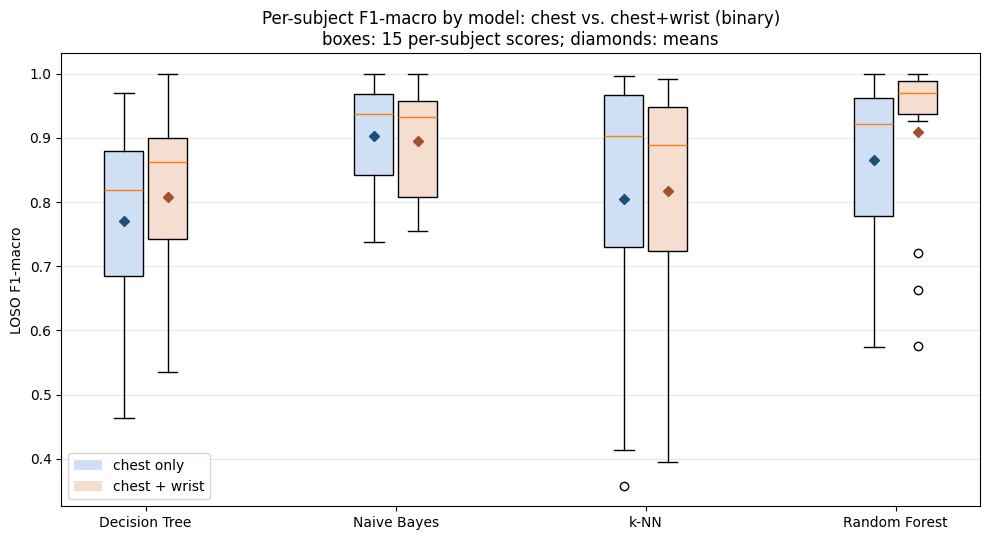

In [18]:
# Boxplots visual analysis for chest vs combined datasets
fig, ax = plt.subplots(figsize=(10, 5.5))
width = 0.35
model_names = list(models)
for i, m in enumerate(model_names):
    b1 = ax.boxplot(results_f1[m], positions=[i * 2 + 1 - width / 2], widths=width * 0.9,
                    patch_artist=True)
    b2 = ax.boxplot(results_f1_combined[m], positions=[i * 2 + 1 + width / 2], widths=width * 0.9,
                    patch_artist=True)
    b1['boxes'][0].set_facecolor('#cfe0f5')
    b2['boxes'][0].set_facecolor('#f5ddcf')

    # Mean marker
    ax.plot(i * 2 + 1 - width / 2, results_f1[m].mean(), marker='D', color='#1f4e79',
            markersize=5, zorder=3)
    ax.plot(i * 2 + 1 + width / 2, results_f1_combined[m].mean(), marker='D', color='#a0522d',
            markersize=5, zorder=3)

ax.set_xticks([i * 2 + 1 for i in range(len(model_names))])
ax.set_xticklabels(model_names)
ax.set_ylabel('LOSO F1-macro')
ax.set_title('Per-subject F1-macro by model: chest vs. chest+wrist (binary)\n'
             'boxes: 15 per-subject scores; diamonds: means')
ax.grid(axis='y', alpha=0.3)
ax.legend([Patch(facecolor='#cfe0f5'), Patch(facecolor='#f5ddcf')],
          ['chest only', 'chest + wrist'])
plt.tight_layout()
plt.show()

## **2. Three-Class Classification pipeline — Baseline vs. Stress vs. Amusement**

### 2.1 Setup and Labels extraction

In [19]:
# Three-class target: original label (1=baseline, 2=stress, 3=amusement)
y_multi = features['label'].values
CLASS_ORDER = [1, 2, 3]
CLASS_LABELS = ['baseline', 'stress', 'amusement']

# Class distribution after segmentation
for lab, name in zip(CLASS_ORDER, CLASS_LABELS):
    n = int((y_multi == lab).sum())
    print(f'{name:10s}: {n} ({n / len(y_multi) * 100:.1f}%)')

baseline  : 3354 (54.8%)
stress    : 1826 (29.8%)
amusement : 943 (15.4%)


### 2.2 Nested LOSO evaluation

In [20]:
def nested_loso_multi(clf, param_grid, X, y, groups):
    """Outer LOSO for evaluation, inner LOSO for tuning for multiclass classification.
    Returns per-subject F1-macro, accuracy, chosen hyperparameters, out-of-fold predictions,
    and the per-outer-fold inner-CV tuning curves."""
    f1_scores, acc_scores, chosen = [], [], []
    y_pred = np.empty_like(y)
    k_curves = []
    for train_idx, test_idx in outer_cv.split(X, y, groups):
        search = GridSearchCV(
            make_pipeline(clf), param_grid,
            scoring='f1_macro', cv=inner_cv, n_jobs=-1,
        )
        search.fit(X[train_idx], y[train_idx], groups=groups[train_idx])
        k_curves.append(_k_curve_from_search(search))
        y_pred[test_idx] = search.predict(X[test_idx])
        f1_scores.append(f1_score(y[test_idx], y_pred[test_idx], average='macro'))
        acc_scores.append(accuracy_score(y[test_idx], y_pred[test_idx]))
        chosen.append(search.best_params_)
    return np.array(f1_scores), np.array(acc_scores), chosen, y_pred, k_curves

# Run nested LOSO for each model on the multiclass target and store results
results_f1_multi, results_acc_multi, results_params_multi, results_pred_multi, results_kcurves_multi = {}, {}, {}, {}, {}
for name, clf in models.items():
    print(f'Evaluating {name} ...')
    f1v, accv, chosen, ypred, kcurves = nested_loso_multi(clf, param_grids[name], X, y_multi, groups)
    results_f1_multi[name] = f1v
    results_acc_multi[name] = accv
    results_params_multi[name] = chosen
    results_pred_multi[name] = ypred
    results_kcurves_multi[name] = kcurves
    print(f'  {name}: F1-macro {f1v.mean():.3f} +/- {f1v.std():.3f}   '
          f'accuracy {accv.mean():.3f} +/- {accv.std():.3f}')

Evaluating Decision Tree ...
  Decision Tree: F1-macro 0.617 +/- 0.186   accuracy 0.751 +/- 0.135
Evaluating Naive Bayes ...
  Naive Bayes: F1-macro 0.765 +/- 0.176   accuracy 0.827 +/- 0.143
Evaluating k-NN ...
  k-NN: F1-macro 0.656 +/- 0.179   accuracy 0.792 +/- 0.115
Evaluating Random Forest ...
  Random Forest: F1-macro 0.716 +/- 0.202   accuracy 0.842 +/- 0.126


### Store, summarize and visualize classification results

In [21]:
# Summarize multiclass results in a DataFrame for comparison
summary_multi = pd.DataFrame({
    'F1-macro (mean)': {m: v.mean() for m, v in results_f1_multi.items()},
    'F1-macro (std)':  {m: v.std()  for m, v in results_f1_multi.items()},
    'Accuracy (mean)': {m: v.mean() for m, v in results_acc_multi.items()},
    'Accuracy (std)':  {m: v.std()  for m, v in results_acc_multi.items()},
}).round(3)
summary_multi

,F1-macro (mean),F1-macro (std),Accuracy (mean),Accuracy (std)
Decision Tree,0.617,0.186,0.751,0.135
Naive Bayes,0.765,0.176,0.827,0.143
k-NN,0.656,0.179,0.792,0.115
Random Forest,0.716,0.202,0.842,0.126


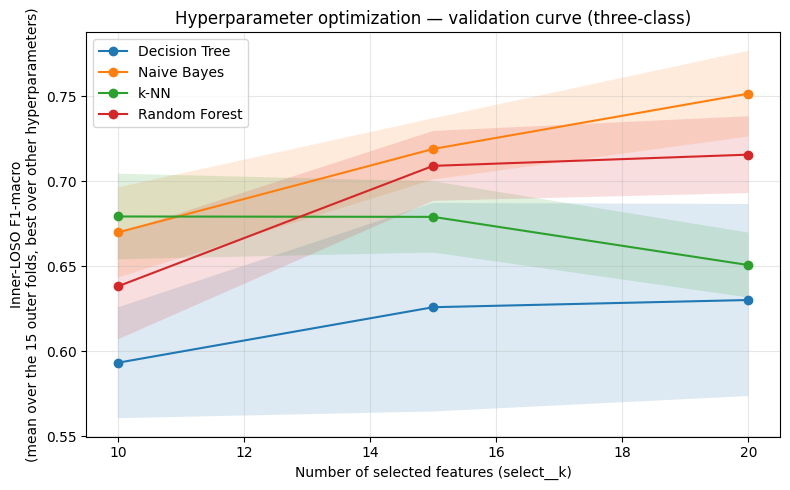

In [22]:
# Plot the nested LOSO tuning curves for the multiclass classification task
plot_nested_k_curves(results_kcurves_multi,
                     'Hyperparameter optimization — validation curve (three-class)')

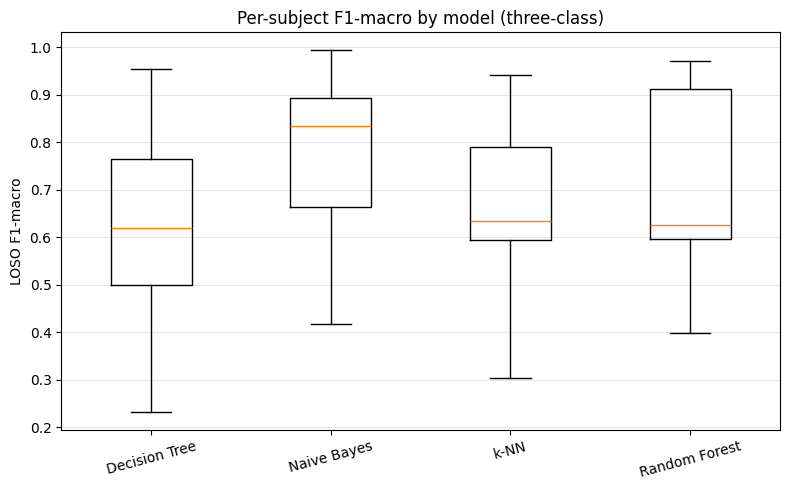

In [23]:
# Per-subject F1-macro distribution by model
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([results_f1_multi[m] for m in models], tick_labels=list(models.keys()))
ax.set_ylabel('LOSO F1-macro')
ax.set_title('Per-subject F1-macro by model (three-class)')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

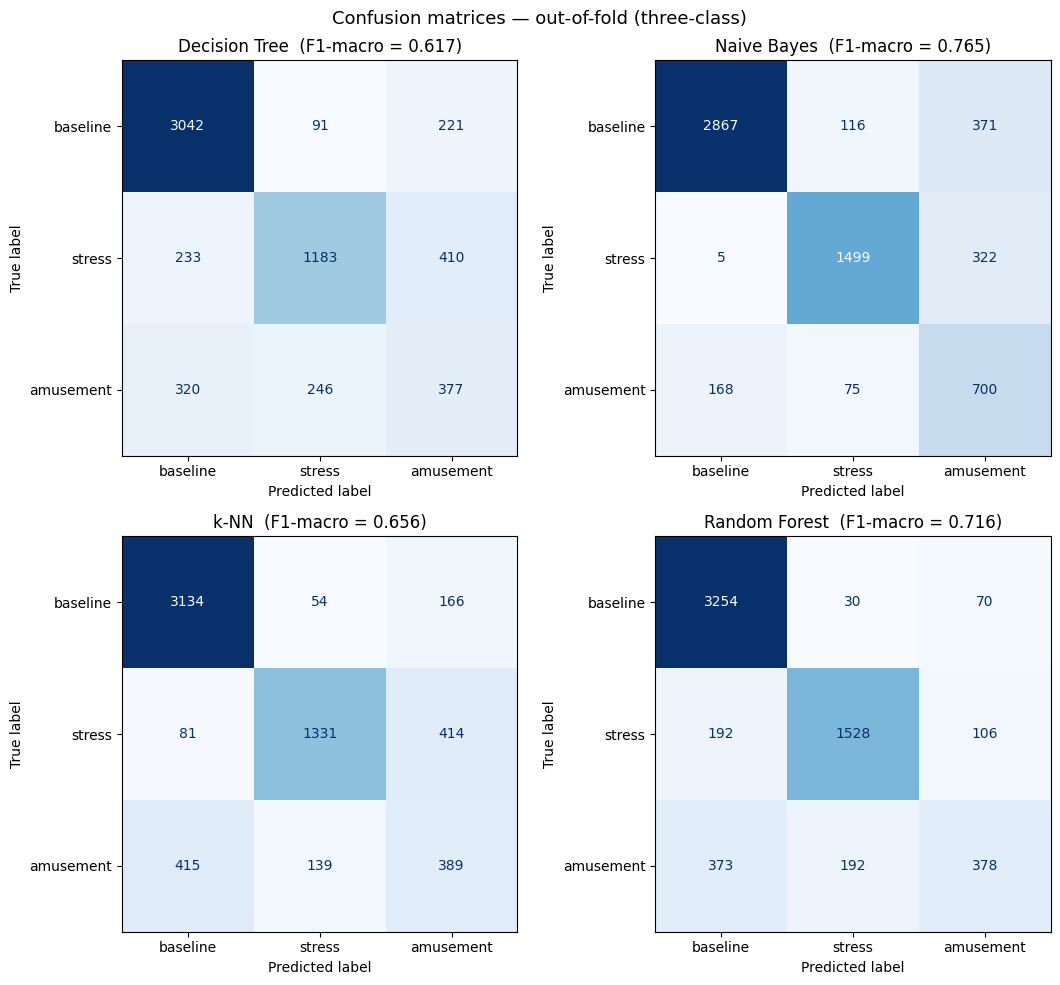

In [24]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_multi, results_pred_multi[name], labels=CLASS_ORDER)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}  (F1-macro = {results_f1_multi[name].mean():.3f})')
fig.suptitle('Confusion matrices — out-of-fold (three-class)', fontsize=13)
plt.tight_layout()
plt.show()

### 2.3 Statistical Comparison

In [25]:
# Statistical analysis: Friedman omnibus test and post-hoc Wilcoxon tests (Holm-corrected)
score_matrix_multi = [results_f1_multi[m] for m in models]
stat_multi, p_friedman_multi = friedmanchisquare(*score_matrix_multi)
print(f'Friedman: chi2 = {stat_multi:.3f}, p = {p_friedman_multi:.4f}')

posthoc_multi = posthoc_table(results_f1_multi, list(models.keys()), p_friedman_multi)
posthoc_multi

Friedman: chi2 = 5.878, p = 0.1177
Friedman not significant: the table below is descriptive only, the pairwise p-values do not constitute inference.


,model A,model B,mean diff (A-B),raw p,Holm p,significant
0,Decision Tree,Naive Bayes,-0.148,0.0353,0.2120,False
1,Decision Tree,k-NN,-0.039,0.5995,1.0000,False
2,Decision Tree,Random Forest,-0.099,0.0566,0.2768,False
3,Naive Bayes,k-NN,0.109,0.0554,0.2768,False
4,Naive Bayes,Random Forest,0.049,0.9341,1.0000,False
5,k-NN,Random Forest,-0.060,0.3894,1.0000,False


### 2.4 SMOTE oversampling
The three-class results show that errors concentrate on the amusement class, the
minority class after segmentation. To test whether this is driven by class imbalance,
SMOTE is applied inside the LOSO folds (via an imblearn pipeline, so synthetic samples
are generated from the training data only and never leak into the held-out subject).
Each model is re-evaluated and compared against its no-SMOTE baseline.

In [26]:
# SMOTE requires the imbalanced-learn pipeline, which applies resampling only during fit
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [27]:
def make_pipeline_smote(clf):
    """SMOTE pipeline definition."""
    return ImbPipeline([
        ('missingness', MissingnessFilter(threshold=NA_THRESHOLD)),
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('redundancy', CorrelationFilter(threshold=0.9, random_state=RANDOM_STATE)),
        ('select', SelectKBest(mi_clf, k=15)),
        ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ('clf', clf),
    ])

# switch off class_weight for SMOTE pipelines, since SMOTE balances the classes
models_smote = {}
for name, clf in models.items():
    c = clone(clf)
    if 'class_weight' in c.get_params():
        c.set_params(class_weight=None)
    models_smote[name] = c

In [28]:
def nested_loso_multi_smote(clf, param_grid, X, y, groups):
    """Multiclass nested LOSO using the SMOTE pipeline."""
    f1_scores, acc_scores, chosen = [], [], []
    y_pred = np.empty_like(y)
    for train_idx, test_idx in outer_cv.split(X, y, groups):
        search = GridSearchCV(
            make_pipeline_smote(clf), param_grid,
            scoring='f1_macro', cv=inner_cv, n_jobs=-1,
        )
        search.fit(X[train_idx], y[train_idx], groups=groups[train_idx])
        y_pred[test_idx] = search.predict(X[test_idx])
        f1_scores.append(f1_score(y[test_idx], y_pred[test_idx], average='macro'))
        acc_scores.append(accuracy_score(y[test_idx], y_pred[test_idx]))
        chosen.append(search.best_params_)
    return np.array(f1_scores), np.array(acc_scores), chosen, y_pred

# Run nested LOSO with SMOTE for each model on the multiclass target and store results
results_f1_smote, results_acc_smote, results_params_smote, results_pred_smote = {}, {}, {}, {}
for name, clf in models_smote.items():
    print(f'Evaluating {name} (SMOTE) ...')
    f1v, accv, chosen, ypred = nested_loso_multi_smote(clf, param_grids[name], X, y_multi, groups)
    results_f1_smote[name] = f1v
    results_acc_smote[name] = accv
    results_params_smote[name] = chosen
    results_pred_smote[name] = ypred
    print(f'  {name}: F1-macro {f1v.mean():.3f} +/- {f1v.std():.3f}   '
          f'accuracy {accv.mean():.3f} +/- {accv.std():.3f}')

Evaluating Decision Tree (SMOTE) ...
  Decision Tree: F1-macro 0.631 +/- 0.201   accuracy 0.755 +/- 0.139
Evaluating Naive Bayes (SMOTE) ...
  Naive Bayes: F1-macro 0.758 +/- 0.163   accuracy 0.816 +/- 0.135
Evaluating k-NN (SMOTE) ...
  k-NN: F1-macro 0.656 +/- 0.175   accuracy 0.786 +/- 0.118
Evaluating Random Forest (SMOTE) ...
  Random Forest: F1-macro 0.727 +/- 0.202   accuracy 0.849 +/- 0.121


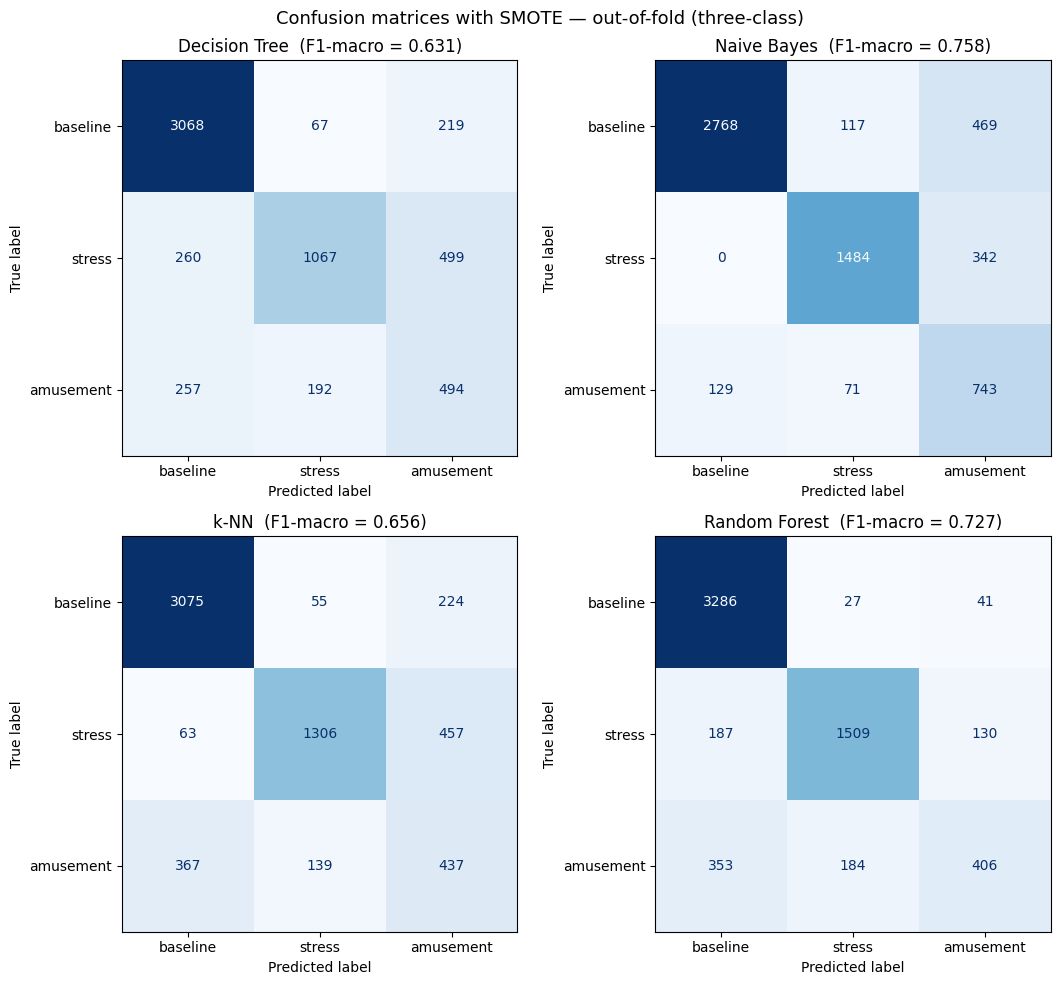

In [29]:
# Confusion matrices with SMOTE 
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_multi, results_pred_smote[name], labels=CLASS_ORDER)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}  (F1-macro = {results_f1_smote[name].mean():.3f})')
fig.suptitle('Confusion matrices with SMOTE — out-of-fold (three-class)', fontsize=13)
plt.tight_layout()
plt.show()

In [30]:
# Paired Wilcoxon per model with Holm correction: no-SMOTE vs SMOTE
raw_p_smote = []
rows_smote = []
for name in model_list:
    a = results_f1_multi[name]        # no SMOTE
    b = results_f1_smote[name]        # SMOTE
    _, p = wilcoxon(a, b, zero_method='pratt')
    raw_p_smote.append(p)
    rows_smote.append({
        'model': name,
        'F1 no-SMOTE': round(a.mean(), 3),
        'F1 SMOTE': round(b.mean(), 3),
        'delta': round(b.mean() - a.mean(), 3),
    })

adj_p_smote = holm_correction(raw_p_smote)
for row, rp, ap in zip(rows_smote, raw_p_smote, adj_p_smote):
    row['raw p'] = round(rp, 4)
    row['Holm p'] = round(ap, 4)
    row['significant'] = ap < 0.05

smote_comparison = pd.DataFrame(rows_smote)
smote_comparison

,model,F1 no-SMOTE,F1 SMOTE,delta,raw p,Holm p,significant
0,Decision Tree,0.617,0.631,0.014,0.4768,0.9537,False
1,Naive Bayes,0.765,0.758,-0.007,0.1632,0.6529,False
2,k-NN,0.656,0.656,0.000,0.9341,0.9537,False
3,Random Forest,0.716,0.727,0.010,0.1632,0.6529,False


,F1-macro (no SMOTE),F1-macro (SMOTE),accuracy (no SMOTE),accuracy (SMOTE),F1 delta
Decision Tree,0.617,0.631,0.751,0.755,0.014
Naive Bayes,0.765,0.758,0.827,0.816,-0.007
k-NN,0.656,0.656,0.792,0.786,0.000
Random Forest,0.716,0.727,0.842,0.849,0.011


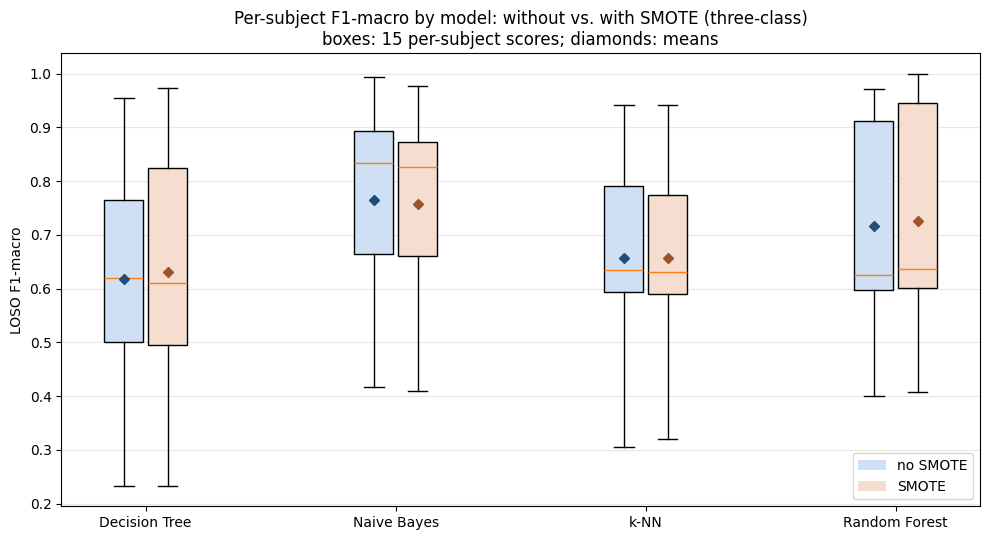

In [31]:
# Compare three-class F1-macro with and without SMOTE
smote_summary = pd.DataFrame({
    'F1-macro (no SMOTE)':   {m: results_f1_multi[m].mean() for m in models},
    'F1-macro (SMOTE)':      {m: results_f1_smote[m].mean() for m in models},
    'accuracy (no SMOTE)':   {m: results_acc_multi[m].mean() for m in models},
    'accuracy (SMOTE)':      {m: results_acc_smote[m].mean() for m in models},
}).round(3)
smote_summary['F1 delta'] = (smote_summary['F1-macro (SMOTE)'] - smote_summary['F1-macro (no SMOTE)']).round(3)
display(smote_summary)

# Boxplots visual analysis: F1-macro with and without SMOTE
fig, ax = plt.subplots(figsize=(10, 5.5))
width = 0.35
model_names = list(models)
for i, m in enumerate(model_names):
    b1 = ax.boxplot(results_f1_multi[m], positions=[i * 2 + 1 - width / 2], widths=width * 0.9,
                    patch_artist=True)
    b2 = ax.boxplot(results_f1_smote[m], positions=[i * 2 + 1 + width / 2], widths=width * 0.9,
                    patch_artist=True)
    b1['boxes'][0].set_facecolor('#cfe0f5')
    b2['boxes'][0].set_facecolor('#f5ddcf')

    # Mean marker
    ax.plot(i * 2 + 1 - width / 2, results_f1_multi[m].mean(), marker='D', color='#1f4e79',
            markersize=5, zorder=3)
    ax.plot(i * 2 + 1 + width / 2, results_f1_smote[m].mean(), marker='D', color='#a0522d',
            markersize=5, zorder=3)

ax.set_xticks([i * 2 + 1 for i in range(len(model_names))])
ax.set_xticklabels(model_names)
ax.set_ylabel('LOSO F1-macro')
ax.set_title('Per-subject F1-macro by model: without vs. with SMOTE (three-class)\n'
             'boxes: 15 per-subject scores; diamonds: means')
ax.grid(axis='y', alpha=0.3)
ax.legend([Patch(facecolor='#cfe0f5'), Patch(facecolor='#f5ddcf')],
          ['no SMOTE', 'SMOTE'])
plt.tight_layout()
plt.show()

### 2.5 Feature-selection analysis
This check probes whether the amusement difficulty comes from the feature-selection step
discarding useful features. The selection frequency
of each feature across the 15 LOSO folds is inspected to verify whether the features
expected to capture amusement, the EDA peak-distribution descriptors (Setz et al.) and the
respiration features, actually survive selection or are systematically discarded.

In [32]:
def selection_frequency(clf, X, y, groups, k=20):
    """Count how often each original feature survives the full selection chain
    (missingness -> correlation -> SelectKBest) across the LOSO folds."""
    counter = Counter()
    feature_names = np.array(feature_cols)
    for train_idx, _ in outer_cv.split(X, y, groups):
        pipe = make_pipeline(clf)
        pipe.set_params(select__k=k)
        pipe.fit(X[train_idx], y[train_idx])
        names = feature_names[pipe.named_steps['missingness'].keep_]
        names = names[pipe.named_steps['redundancy'].keep_]
        names = names[pipe.named_steps['select'].get_support()]
        counter.update(names.tolist())
    return counter

# Compute feature selection frequency for the three-class task using GaussianNB
freq = selection_frequency(GaussianNB(), X, y_multi, groups, k=20)
n_folds = len(np.unique(groups))

freq_df = pd.DataFrame(freq.most_common(), columns=['feature', 'folds_selected'])
freq_df['fraction'] = (freq_df['folds_selected'] / n_folds).round(2)
print(f'Features selected in the three-class task (k=20, {n_folds} folds):')
freq_df

Features selected in the three-class task (k=20, 15 folds):


,feature,folds_selected,fraction
0,HRV_pNN50,15,1.00
1,EDA_max,15,1.00
2,TEMP_range,15,1.00
3,HR_mean_rel,15,1.00
4,HRV_pNN50_rel,15,1.00
5,EDA_max_rel,15,1.00
6,EDA_range_rel,15,1.00
7,SCR_amp_mean_rel,15,1.00
8,SCR_amp_std_rel,15,1.00
9,EDA_psd_power_rel,15,1.00


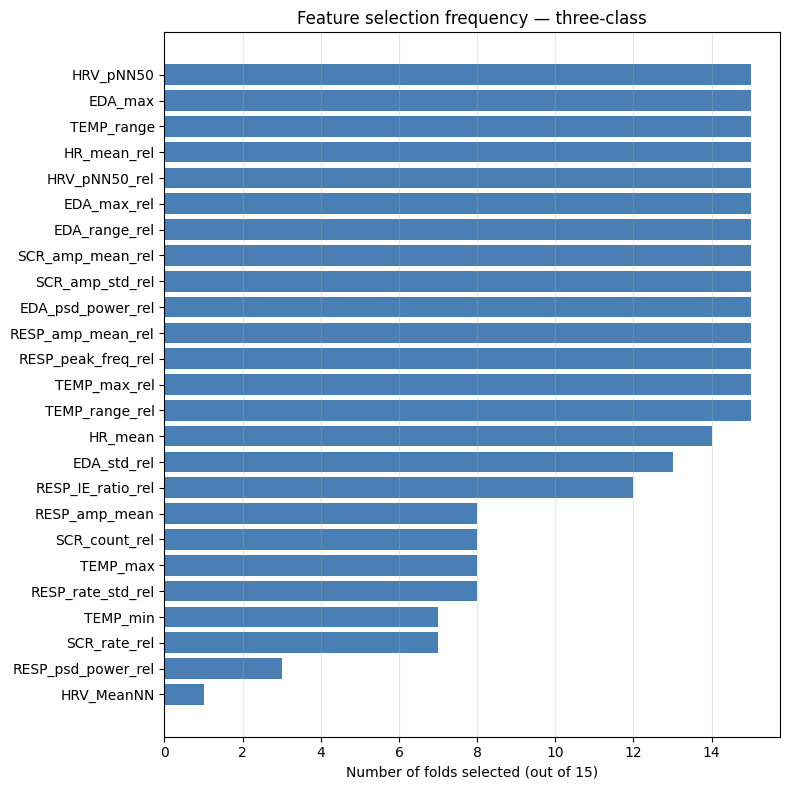

In [33]:
# Bar chart of selection frequency
top = freq_df.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top['feature'], top['folds_selected'], color='#4a7fb5')
ax.set_xlabel(f'Number of folds selected (out of {n_folds})')
ax.set_title('Feature selection frequency — three-class')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 2.6 Device comparison — chest vs. chest+wrist

In [34]:
# Combined dataset evaluation for the three-class target
yc_multi = combined['label'].values

# Scaled feature grid for the combined dataset (three-class)
K_GRID_COMBINED_MULTI = [20, 40, 'all']
param_grids_combined_multi = grids_with_k(param_grids, K_GRID_COMBINED_MULTI)

# Evaluate all four models on the combined table for the three-class target
results_f1_multi_combined, results_acc_multi_combined = {}, {}
for name, clf in models.items():
    print(f'Evaluating {name} (combined) ...')
    f1v, accv, _, _, _ = nested_loso_multi(clf, param_grids_combined_multi[name], Xc, yc_multi, groups_c)
    results_f1_multi_combined[name] = f1v
    results_acc_multi_combined[name] = accv
    print(f'  {name}: combined F1-macro {f1v.mean():.3f} +/- {f1v.std():.3f}')

Evaluating Decision Tree (combined) ...
  Decision Tree: combined F1-macro 0.647 +/- 0.164
Evaluating Naive Bayes (combined) ...
  Naive Bayes: combined F1-macro 0.737 +/- 0.199
Evaluating k-NN (combined) ...
  k-NN: combined F1-macro 0.665 +/- 0.124
Evaluating Random Forest (combined) ...
  Random Forest: combined F1-macro 0.736 +/- 0.163


In [35]:
# Paired Wilcoxon per model with Holm correction: chest vs combined (three-class)
model_list = list(models)
raw_p_dev = []
rows_dev = []
for name in model_list:
    a = results_f1_multi[name]
    b = results_f1_multi_combined[name]
    _, p = wilcoxon(a, b, zero_method='pratt')
    raw_p_dev.append(p)
    rows_dev.append({
        'model': name,
        'chest F1': round(a.mean(), 3),
        'combined F1': round(b.mean(), 3),
        'delta': round(b.mean() - a.mean(), 3),
    })

adj_p_dev = holm_correction(raw_p_dev)
for row, rp, ap in zip(rows_dev, raw_p_dev, adj_p_dev):
    row['raw p'] = round(rp, 4)
    row['Holm p'] = round(ap, 4)
    row['significant'] = ap < 0.05

device_comparison_multi = pd.DataFrame(rows_dev)
device_comparison_multi

,model,chest F1,combined F1,delta,raw p,Holm p,significant
0,Decision Tree,0.617,0.647,0.030,0.3303,0.8036,False
1,Naive Bayes,0.765,0.737,-0.029,0.1354,0.5415,False
2,k-NN,0.656,0.665,0.008,0.5614,0.8036,False
3,Random Forest,0.716,0.736,0.019,0.2679,0.8036,False


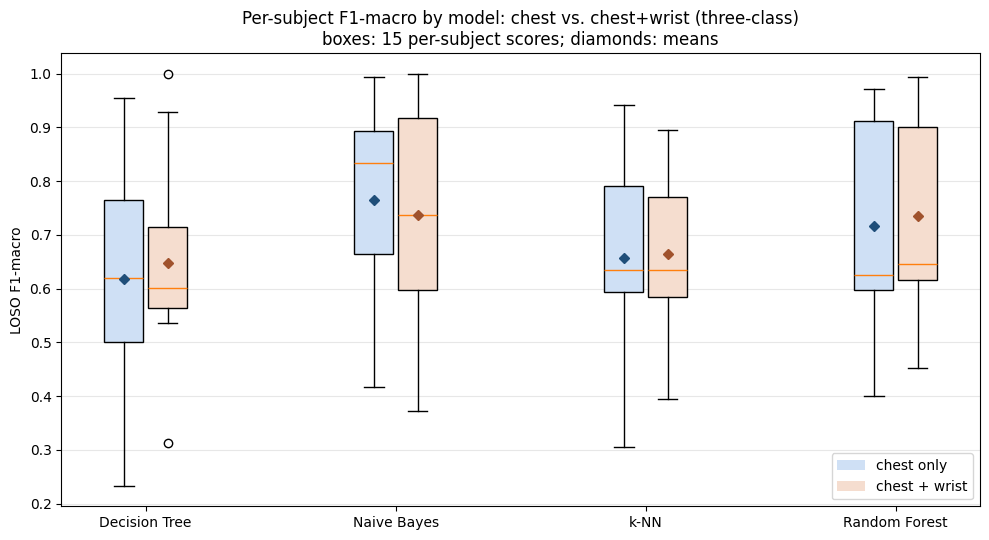

In [36]:
# Boxplots visual analysis: F1-macro with chest vs combined (three-class)
fig, ax = plt.subplots(figsize=(10, 5.5))
width = 0.35
model_names = list(models)
for i, m in enumerate(model_names):
    b1 = ax.boxplot(results_f1_multi[m], positions=[i * 2 + 1 - width / 2], widths=width * 0.9,
                    patch_artist=True)
    b2 = ax.boxplot(results_f1_multi_combined[m], positions=[i * 2 + 1 + width / 2], widths=width * 0.9,
                    patch_artist=True)
    b1['boxes'][0].set_facecolor('#cfe0f5')
    b2['boxes'][0].set_facecolor('#f5ddcf')

    # Mean marker
    ax.plot(i * 2 + 1 - width / 2, results_f1_multi[m].mean(), marker='D', color='#1f4e79',
            markersize=5, zorder=3)
    ax.plot(i * 2 + 1 + width / 2, results_f1_multi_combined[m].mean(), marker='D', color='#a0522d',
            markersize=5, zorder=3)

ax.set_xticks([i * 2 + 1 for i in range(len(model_names))])
ax.set_xticklabels(model_names)
ax.set_ylabel('LOSO F1-macro')
ax.set_title('Per-subject F1-macro by model: chest vs. chest+wrist (three-class)\n'
             'boxes: 15 per-subject scores; diamonds: means')
ax.grid(axis='y', alpha=0.3)
ax.legend([Patch(facecolor='#cfe0f5'), Patch(facecolor='#f5ddcf')],
          ['chest only', 'chest + wrist'])
plt.tight_layout()
plt.show()

## **3. Explainability (SHAP)**

Because the statistical comparison finds the four models equivalent, the explainability
analysis is carried out on Random Forest, which supports fast, exact tree-based SHAP through
TreeExplainer. To keep the computation tractable while avoiding leakage, a single subject-wise
train/test split is used: the full pipeline (selection, scaling, model) is fitted on the
training subjects only, and SHAP values are computed on the held-out test subjects, data the
model never saw. 

In [37]:
# Hold out split for SHAP analysis: 4 subjects for testing, 11 for training
subjects = np.unique(groups) 
rng = np.random.default_rng(RANDOM_STATE)
test_subjects = rng.choice(subjects, size=4, replace=False)
train_mask = ~np.isin(groups, test_subjects)
test_mask = np.isin(groups, test_subjects)
print(f'train subjects: {sorted(subjects[~np.isin(subjects, test_subjects)])}')
print(f'test subjects:  {sorted(test_subjects)}')

X_tr, y_tr = X[train_mask], y_multi[train_mask]
X_te, y_te = X[test_mask], y_multi[test_mask]

# Modal configuration chosen by the nested LOSO search for Random Forest
rf_modal = dict(Counter(tuple(sorted(p.items()))
                        for p in results_params_multi['Random Forest']).most_common(1)[0][0])
print(f'modal Random Forest configuration: {rf_modal}')

# SHAP pipeline: missingness filter, median imputation, scaling, correlation filter, feature selection, and Random Forest classifier
shap_pipe = Pipeline([
    ('missingness', MissingnessFilter(threshold=NA_THRESHOLD)),
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('redundancy', CorrelationFilter(threshold=0.9, random_state=RANDOM_STATE)),
    ('select', SelectKBest(mi_clf, k=rf_modal['select__k'])),
    ('clf', RandomForestClassifier(class_weight='balanced',
                                   n_estimators=rf_modal['clf__n_estimators'],
                                   max_depth=rf_modal['clf__max_depth'],
                                   random_state=RANDOM_STATE)),
])
shap_pipe.fit(X_tr, y_tr)
print(f'(diagnostic) test F1-macro: {f1_score(y_te, shap_pipe.predict(X_te), average="macro"):.3f}')

train subjects: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17)]
test subjects:  [np.int64(6), np.int64(9), np.int64(10), np.int64(13)]
modal Random Forest configuration: {'clf__max_depth': 10, 'clf__n_estimators': 400, 'select__k': 20}
(diagnostic) test F1-macro: 0.901


In [38]:
# Recover the names of the features explained by SHAP (after all preprocessing steps)
feature_names = np.array(feature_cols)
names_after_miss = feature_names[shap_pipe.named_steps['missingness'].keep_]
names_after_corr = names_after_miss[shap_pipe.named_steps['redundancy'].keep_]
selected_names = names_after_corr[shap_pipe.named_steps['select'].get_support()]

# Apply preprocessing
X_te_pre = shap_pipe[:-1].transform(X_te)
rf = shap_pipe.named_steps['clf']

# TreeExplainer: exact SHAP for tree ensembles
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_te_pre)

# Organize SHAP values by class
if isinstance(shap_values, list):
    shap_by_class = shap_values                                 
else:
    shap_by_class = [shap_values[:, :, c] for c in range(shap_values.shape[2])]  

class_names = ['baseline', 'stress', 'amusement']
print(f'SHAP computed on {X_te_pre.shape[0]} held-out windows, {X_te_pre.shape[1]} features')

SHAP computed on 1646 held-out windows, 20 features


--- baseline ---


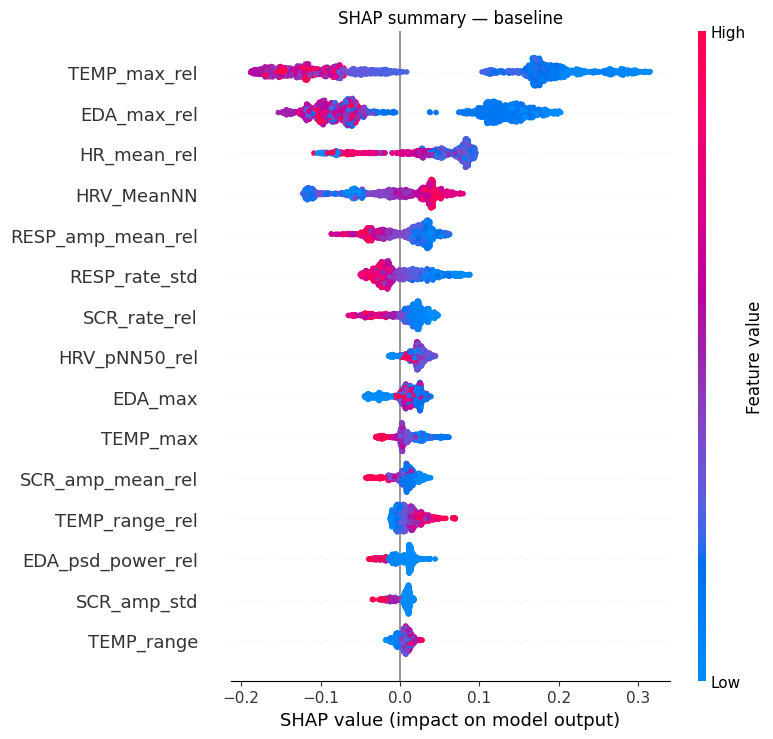

--- stress ---


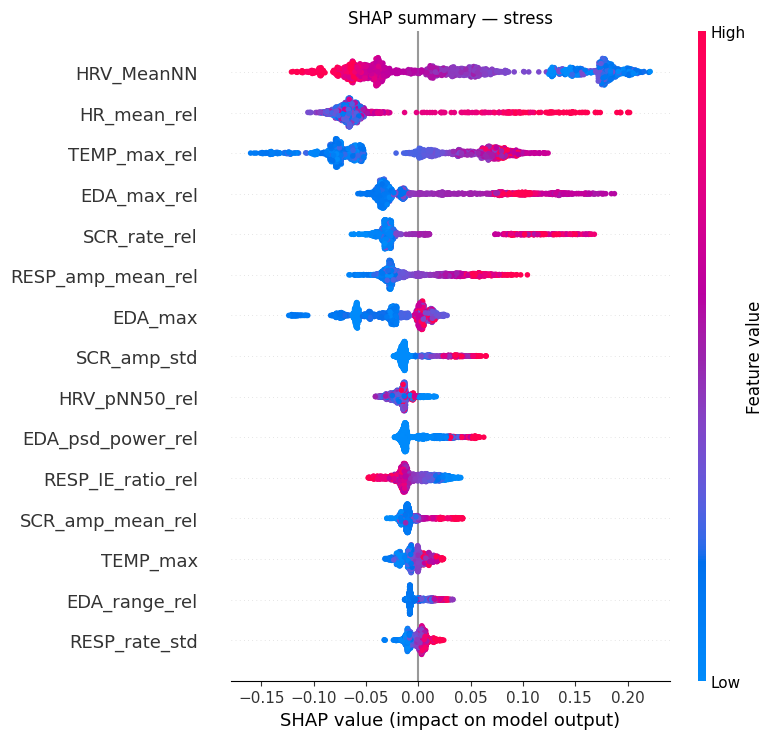

--- amusement ---


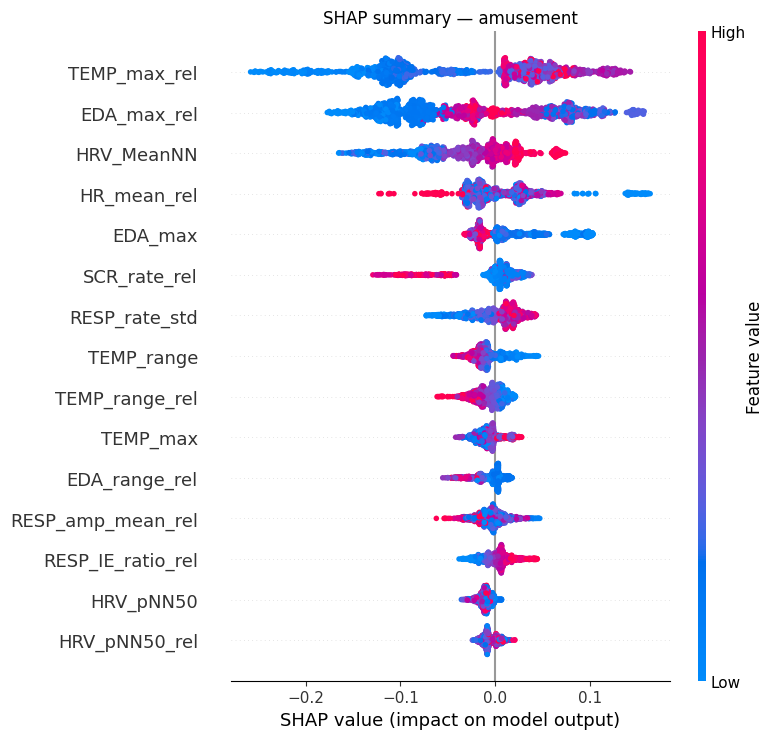

In [39]:
# Global feature importance: one summary (beeswarm) per class
for c, cname in enumerate(class_names):
    print(f'--- {cname} ---')
    shap.summary_plot(shap_by_class[c], X_te_pre, feature_names=selected_names,
                      show=False, max_display=15)
    plt.title(f'SHAP summary — {cname}')
    plt.tight_layout()
    plt.show()

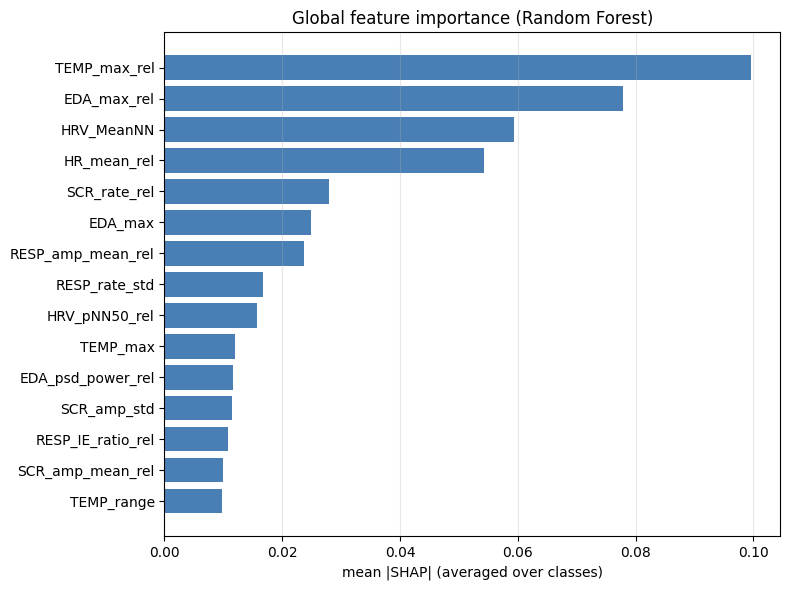

In [40]:
# Compact global view: mean |SHAP| per feature, averaged across classes
mean_abs = np.mean([np.abs(sc).mean(axis=0) for sc in shap_by_class], axis=0)
order = np.argsort(mean_abs)[::-1][:15]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(np.array(selected_names)[order][::-1], mean_abs[order][::-1], color='#4a7fb5')
ax.set_xlabel('mean |SHAP| (averaged over classes)')
ax.set_title('Global feature importance (Random Forest)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

--- amusement, correctly classified (predicted: amusement) ---


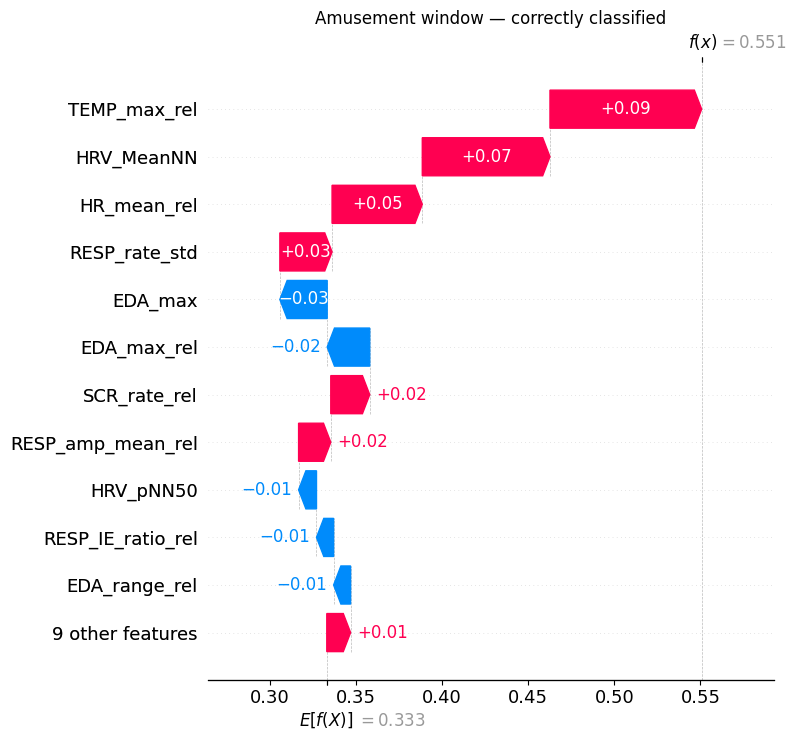

--- amusement, misclassified (predicted: stress) ---


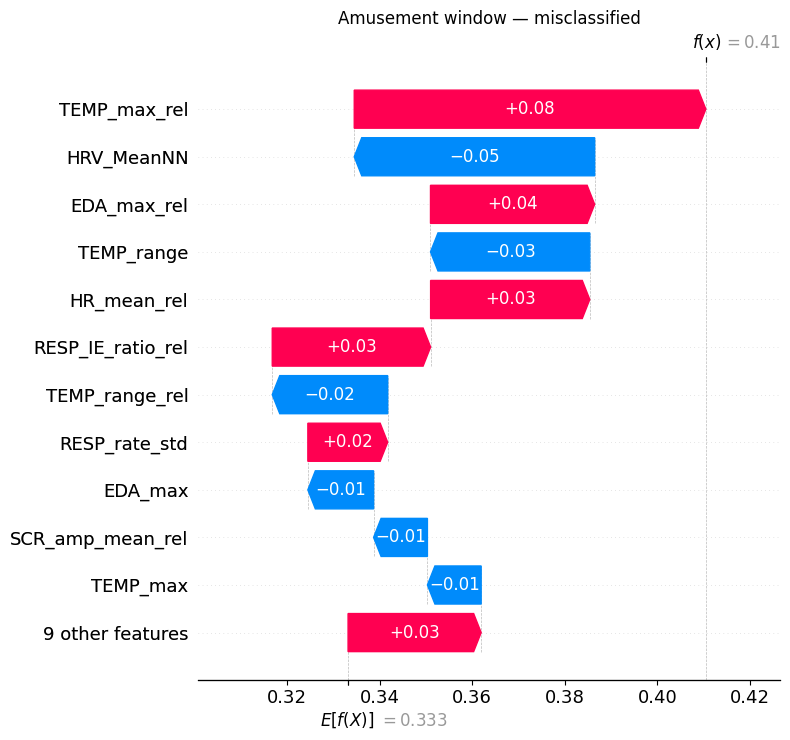

In [41]:
# Pick one correctly classified and one misclassified amusement window from the test set
y_te_pred = shap_pipe.predict(X_te)
amuse_idx = np.where(y_te == 3)[0]
correct_amuse = [i for i in amuse_idx if y_te_pred[i] == 3]
wrong_amuse = [i for i in amuse_idx if y_te_pred[i] != 3]

amuse_class = class_names.index('amusement')  # explain the amusement output
base_value = explainer.expected_value[amuse_class]

for label, idx_list in [('correctly classified', correct_amuse), ('misclassified', wrong_amuse)]:
    if not idx_list:
        print(f'no {label} amusement in test set')
        continue
    i = idx_list[0]
    print(f'--- amusement, {label} (predicted: {class_names[y_te_pred[i] - 1]}) ---')
    shap.plots._waterfall.waterfall_legacy(
        base_value,
        shap_by_class[amuse_class][i],
        feature_names=selected_names,
        max_display=12, show=False)
    plt.title(f'Amusement window — {label}')
    plt.tight_layout()
    plt.show()

In [42]:
# Cross-check: do SHAP-important features match those selected most often in the LOSO folds?
shap_importance = pd.DataFrame({
    'feature': selected_names,
    'mean_abs_shap': mean_abs,
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)

cross = (shap_importance
         .merge(freq_df[['feature', 'folds_selected']], on='feature', how='left')
         .fillna({'folds_selected': 0}))
cross['rank_shap'] = cross['mean_abs_shap'].rank(ascending=False).astype(int)
cross['folds_selected'] = cross['folds_selected'].astype(int)
print('Top features by SHAP importance, with selection frequency:')
cross.head(15)

Top features by SHAP importance, with selection frequency:


,feature,mean_abs_shap,folds_selected,rank_shap
0,TEMP_max_rel,0.099540,15,1
1,EDA_max_rel,0.077796,15,2
2,HRV_MeanNN,0.059320,1,3
3,HR_mean_rel,0.054184,15,4
4,SCR_rate_rel,0.027930,7,5
5,EDA_max,0.024945,15,6
6,RESP_amp_mean_rel,0.023728,15,7
7,RESP_rate_std,0.016702,0,8
8,HRV_pNN50_rel,0.015633,15,9
9,TEMP_max,0.011935,8,10
